# Etapa 4 — Submissão final, estimativa do F1-macro e explicabilidade

**Disciplina:** Inteligência Artificial — Profa. Cristiane Neri Nobre
**Trabalho em competição:** Detecção de Intrusão em Redes (NSL-KDD, base atualizada)
**Equipe:** grupo 7 do Canvas (_integrantes: preencher_)
**Etapa 4 — entrega 28/11/2026**

**Objetivo.** Aplicar o modelo congelado na Etapa 3 (`results/final_config.json`) ao arquivo
`teste_sem_rotulo.csv` **uma única vez**, gerar `results/submissao_7.csv`, estimar o F1-macro
esperado no teste usando só o treino e explicar o modelo final.

**O teste não tem rótulos.** Quem calcula o F1-macro oficial é a professora. Toda métrica deste
notebook vem de validação cruzada no treino e é uma **estimativa** do desempenho no teste.

**Resumo dos resultados**

- **Modelo:** HistGradientBoosting com categorias e ausentes nativos, treinado sem as cópias e sem
  os grupos de rótulos contraditórios (`drop_inconsistent`), com limiar de decisão 0,03 aprendido
  por validação cruzada no treino. Só os 41 atributos de rede (40 após tirar o constante).
- **F1-macro estimado no teste: 0,8819 ± 0,0030** (CV agrupada 3×5 no treino, todas as linhas,
  como a métrica oficial), refeito aqui do zero e igual ao valor congelado na Etapa 3. Os 15 folds
  vão de 0,874 a 0,887. Por classe: `normal` precisão 0,987 / recall 0,984 / F1 0,986;
  `anomaly` precisão 0,759 / recall 0,798 / F1 0,778.
- **Por que não é maior:** o treino tem 1.702 grupos de linhas idênticas com rótulos opostos, que
  nenhum modelo acerta por inteiro. O teto teórico do F1-macro é 0,905; o modelo fica 0,02 abaixo.
  Fora desses grupos, ele erra 145 de 66.103 linhas (F1-macro 0,983).
- **Submissão:** `results/submissao_7.csv` gerado uma única vez, validado contra
  `modelo_de_submissao.csv`; o SHA-256 está na Seção 4 e em `results/submissao_7.sha256`.
- **Explicabilidade:** `service`, `dst_bytes`, `src_bytes`, `flag` e as taxas de erro por host
  dominam (permutação e SHAP concordam). Uma árvore de profundidade 4 imita o modelo em 98,4% das
  linhas. Nenhuma coluna de vazamento chega ao modelo.

**Índice**
0. Configuração e política de dados
1. Modelo congelado
2. Estimativa do F1-macro (validação cruzada no treino)
3. Treino do modelo final
4. Submissão (único uso do teste)
5. Explicabilidade do modelo final
6. Discussão dos resultados
7. Conclusões e checklist de entrega

## 0. Configuração e política de dados

Bibliotecas, semente global e o treino (só os 41 atributos de rede, o rótulo e o grupo de
duplicatas de cada linha, usado para que cópias nunca fiquem em lados opostos da validação).

In [1]:
import json
import time
import warnings; warnings.filterwarnings("ignore")
import joblib
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, sklearn, imblearn, shap
from IPython.display import display
from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedGroupKFold
from nslkdd import (ExperimentLog, ThresholdClassifier, build_pipeline, config, load_test,
                    load_train, write_submission)
from nslkdd.data import check_submission, conflict_mask, evaluation_mask
from nslkdd.decision import GRID, best_threshold, cross_val_proba, macro_f1_curve, positive_proba
from nslkdd.evaluation import binary_metrics, validation_report
from nslkdd.explain import anomaly_log_odds, shap_values, surrogate_rules, transformed
from nslkdd.models import make_model

X, y, groups = load_train()
np.random.seed(config.RANDOM_STATE)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")
config.FIGURES.mkdir(parents=True, exist_ok=True)
config.MODELS.mkdir(parents=True, exist_ok=True)
FOLD_JOBS = 5  # folds da CV em paralelo

print({m.__name__: m.__version__ for m in (np, pd, sklearn, imblearn, shap)})
print("RANDOM_STATE =", config.RANDOM_STATE)
print("X:", X.shape, "| classes:", y.value_counts().to_dict())

{'numpy': '2.5.4', 'pandas': '3.0.6', 'sklearn': '1.9.1', 'imblearn': '0.14.2', 'shap': '0.54.1'}
RANDOM_STATE = 42
X: (69833, 41) | classes: {'normal': 65754, 'anomaly': 4079}


**Política de dados.**
- Todas as decisões (pré-processamento, algoritmo, hiperparâmetros, limiar) foram tomadas nas
  Etapas 2 e 3, por validação cruzada no treino, e congeladas em `results/final_config.json`
  antes deste notebook. Aqui nada é escolhido de novo.
- O teste é carregado **uma única vez**, na Seção 4, depois do treino do modelo final, sem
  remover, alterar ou reordenar linhas. Não há pseudo-rótulos nem ajuste de limiar pelo teste.
- Só os 41 atributos de rede (`config.FEATURES`) são preditores. As colunas de vazamento
  (`score_ids_legado`, `tipo_alerta_soc`, `tempo_resposta_analista_min`) e as 5 cópias derivadas
  ficam de fora, também no teste, onde existem. `data/raw/` (NSL-KDD original) não é usada.

## 1. Modelo congelado

O arquivo `final_config.json` descreve o modelo escolhido na Etapa 3: algoritmo,
hiperparâmetros, pré-processamento e o F1-macro de CV que motivou a escolha. O pipeline é
reconstruído a partir dele e conferido contra o registro de experimentos: a mesma chave
(hash dos parâmetros) prova que é exatamente o pipeline avaliado na Etapa 3.

In [2]:
cfg = json.loads((config.RESULTS / "final_config.json").read_text(encoding="utf-8"))


def build_final():
    """Pipeline do modelo final, montado só a partir de final_config.json."""
    return build_pipeline(make_model(cfg["model"], 1, **cfg["model_params"]),
                          **cfg["pipeline_params"])


log = ExperimentLog()
assert log.data_version == cfg["data_version"], "a base mudou desde o congelamento"
found = log.lookup("etapa3_final", "HGB busca 2", build_final(),
                   {"redundancy": cfg["pipeline_params"]["redundancy"], "repeticoes": 3},
                   n_splits=5, n_repeats=3)
print("Pipeline reconstruído = pipeline avaliado na Etapa 3:", found is not None)
display(pd.Series({**{f"modelo: {k}": v for k, v in cfg["model_params"].items()},
                   **{f"pré-proc.: {k}": v for k, v in cfg["pipeline_params"].items()},
                   "F1-macro CV 3x5 (Etapa 3)": f"{cfg['cv_f1_macro']:.4f} ± {cfg['cv_f1_macro_std']:.4f}"},
                  name="valor").to_frame())
build_final()

Pipeline reconstruído = pipeline avaliado na Etapa 3: True


,valor
modelo: min_samples_leaf,20
modelo: max_leaf_nodes,63
modelo: max_iter,500
modelo: max_features,0.7
modelo: learning_rate,0.08
modelo: l2_regularization,0.0
pré-proc.: redundancy,drop_inconsistent
pré-proc.: domain,nan
pré-proc.: imputation,none
pré-proc.: scaling,none


,steps,"[('redundancy', ...), ('domain', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,func,<function _re...00234161E3CE0>
,kw_args,{'strategy': 'drop_inconsistent'}
,validate,False
,accept_sparse,True
,strategy,'nan'
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('service', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False


**Como o modelo funciona, passo a passo:**
1. `redundancy = drop_inconsistent` — **só no ajuste**: remove cópias e os grupos de linhas
   idênticas com rótulos opostos. É um *sampler* do imbalanced-learn, então nunca toca o teste
   nem o fold de validação.
2. `domain = nan` — valores impossíveis pela definição do atributo (taxa > 1, contagem acima da
   janela, negativos) viram ausentes. É uma regra fixa por linha, sem nada aprendido.
3. Categóricos (`protocol_type`, `service`, `flag`) em códigos ordinais, tratados como
   **categorias nativas** pelo HistGradientBoosting; ausentes ficam como `NaN`, que o modelo
   trata nativamente (sem imputação). `num_outbound_cmds` (constante no treino) sai.
4. HistGradientBoosting com os hiperparâmetros da busca ampliada da Etapa 3.
5. Limiar de decisão aprendido por validação cruzada no treino (`ThresholdClassifier`, Seção 3).

## 2. Estimativa do F1-macro (validação cruzada no treino)

Como o teste não tem rótulos, o desempenho esperado é estimado no treino, com o mesmo protocolo
usado para escolher o modelo:

- **`StratifiedGroupKFold` com 5 folds, repetido 3 vezes** (sementes 42, 43 e 44), estratificado
  pela classe e **agrupado por duplicata**: linhas idênticas ficam sempre no mesmo fold. Sem
  isso, a cópia de uma linha estaria no treino e a outra na validação, e a nota sairia inflada.
- Em cada fold, o pipeline inteiro é ajustado só nos outros 4 folds (limpeza, codificação e
  modelo). O fold de fora recebe P(anomaly).
- **Limiar cruzado:** o limiar de cada fold é o de maior F1-macro nas previsões *dos outros
  folds*. O fold pontuado não ajuda a escolher o próprio limiar.
- **F1-macro em todas as linhas do fold**, com cópias e conflitos, porque é assim que a
  professora calcula a métrica oficial no teste:
  $\text{F1-macro} = \frac{1}{2}\left(F1_{\text{normal}} + F1_{\text{anomaly}}\right)$,
  com $F1_c = \frac{2\,TP_c}{2\,TP_c + FP_c + FN_c}$ para cada classe $c$.
- A estimativa é a média dos 15 folds, e o desvio-padrão entre folds mede a incerteza.

O cálculo é refeito aqui do zero, sem ler o registro de experimentos, para mostrar de onde vem o
número.

In [3]:
SEEDS = [config.RANDOM_STATE + r for r in range(3)]
METRICS = ["f1_macro", "f1_normal", "f1_anomaly", "precision_normal", "recall_normal",
           "precision_anomaly", "recall_anomaly", "accuracy"]
pos = (y == config.POSITIVE).to_numpy()
conflict = conflict_mask(groups, y)

t0 = time.time()
rows, oof = [], {}
for r, seed in enumerate(SEEDS):
    proba, fold = cross_val_proba(build_final(), X, y, groups, n_splits=5, seed=seed,
                                  n_jobs=FOLD_JOBS)
    pred = np.zeros(len(X), dtype=bool)
    for k in range(5):
        own = fold == k
        thr = best_threshold(proba[~own], pos[~own])  # limiar aprendido nos outros folds
        pred[own] = proba[own] >= thr
        m = binary_metrics(pos[own], pred[own])
        rows.append({"repetição": r + 1, "semente": seed, "fold": k + 1, "linhas": int(own.sum()),
                     "limiar": thr, **{name: m[name] for name in METRICS}})
    oof[seed] = {"proba": proba, "fold": fold, "pred": pred}
folds = pd.DataFrame(rows)
print(f"CV 3x5 refeita em {time.time() - t0:.0f} s")
display(folds.round(4))

CV 3x5 refeita em 50 s


,repetição,semente,fold,linhas,limiar,f1_macro,f1_normal,f1_anomaly,precision_normal,recall_normal,precision_anomaly,recall_anomaly,accuracy
0,1,42,1,13967,0.03,0.8837,0.9860,0.7815,0.9879,0.9840,0.7581,0.8064,0.9737
1,1,42,2,13968,0.03,0.8834,0.9859,0.7808,0.9880,0.9838,0.7557,0.8076,0.9735
2,1,42,3,13966,0.04,0.8832,0.9860,0.7804,0.9876,0.9843,0.7605,0.8015,0.9737
3,1,42,4,13966,0.03,0.8822,0.9860,0.7784,0.9872,0.9847,0.7633,0.7941,0.9736
4,1,42,5,13966,0.03,0.8815,0.9857,0.7773,0.9879,0.9835,0.7514,0.8049,0.9731
5,2,43,1,13967,0.03,0.8832,0.9862,0.7801,0.9869,0.9855,0.7713,0.7892,0.9740
6,2,43,2,13966,0.05,0.8832,0.9861,0.7802,0.9870,0.9852,0.7690,0.7917,0.9739
7,2,43,3,13968,0.08,0.8797,0.9854,0.7741,0.9879,0.9828,0.7443,0.8064,0.9725
8,2,43,4,13966,0.10,0.8774,0.9854,0.7694,0.9866,0.9843,0.7553,0.7840,0.9726
9,2,43,5,13966,0.08,0.8796,0.9857,0.7734,0.9866,0.9849,0.7628,0.7843,0.9731


Cada linha acima é um fold: um modelo treinado em ~80% do treino e pontuado nos ~20% restantes,
que ele nunca viu. A estimativa final é a média desses 15 valores:

In [4]:
f1_mean, f1_std = folds["f1_macro"].mean(), folds["f1_macro"].std(ddof=0)
print(f"F1-macro estimado (CV agrupada 3x5, todas as linhas): {f1_mean:.4f} ± {f1_std:.4f}")
print(f"Valor registrado no congelamento (Etapa 3):          {cfg['cv_f1_macro']:.4f} ± "
      f"{cfg['cv_f1_macro_std']:.4f}")
print(f"Faixa entre folds: {folds['f1_macro'].min():.4f} a {folds['f1_macro'].max():.4f}")
assert abs(f1_mean - cfg["cv_f1_macro"]) < 1e-3, "a CV refeita não reproduz a da Etapa 3"

per_class = pd.DataFrame({
    "precisão": [folds["precision_normal"].mean(), folds["precision_anomaly"].mean()],
    "recall": [folds["recall_normal"].mean(), folds["recall_anomaly"].mean()],
    "F1": [folds["f1_normal"].mean(), folds["f1_anomaly"].mean()],
}, index=["normal", "anomaly"])
per_class.loc["média macro"] = per_class.mean()
print("\nMétricas por classe (média dos 15 folds) — as que a professora vai divulgar:")
display(per_class.round(4))

F1-macro estimado (CV agrupada 3x5, todas as linhas): 0.8819 ± 0.0030
Valor registrado no congelamento (Etapa 3):          0.8819 ± 0.0030
Faixa entre folds: 0.8741 a 0.8871

Métricas por classe (média dos 15 folds) — as que a professora vai divulgar:


,precisão,recall,F1
normal,0.9874,0.9843,0.9858
anomaly,0.7588,0.7982,0.7779
média macro,0.8731,0.8912,0.8819


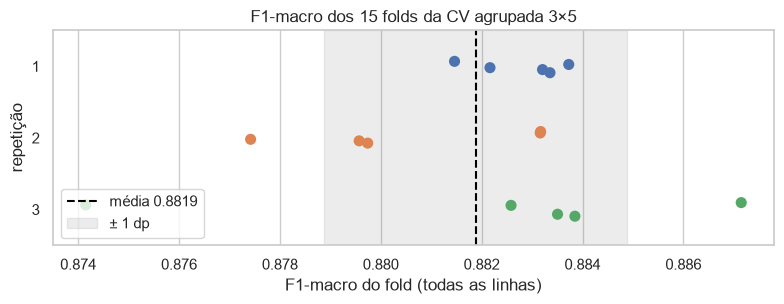

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.2))
sns.stripplot(data=folds, x="f1_macro", y=folds["repetição"].astype(str), hue="repetição",
              palette="deep", size=8, legend=False, ax=ax)
ax.axvline(f1_mean, color="black", ls="--", label=f"média {f1_mean:.4f}")
ax.axvspan(f1_mean - f1_std, f1_mean + f1_std, color="grey", alpha=0.15, label="± 1 dp")
ax.set_xlabel("F1-macro do fold (todas as linhas)")
ax.set_ylabel("repetição")
ax.set_title("F1-macro dos 15 folds da CV agrupada 3×5")
ax.legend(loc="lower left")
fig.tight_layout()
fig.savefig(config.FIGURES / "final_f1_folds.png", dpi=150, bbox_inches="tight")
plt.show()

**O que se conclui.**
- A CV refeita neste notebook dá **0,8819 ± 0,0030**, exatamente o valor que levou à escolha do
  modelo na Etapa 3. O número é reprodutível e não depende do registro de experimentos.
- Os 15 folds ficam entre 0,874 e 0,887. Essa faixa mostra a variação esperada só por qual
  amostra de ~14 mil linhas é avaliada; o teste, com 24.333 linhas, deve variar um pouco menos.
- O F1-macro é a média de duas classes muito diferentes: `normal` tem F1 0,986 e `anomaly`,
  0,778. A classe rara puxa a média para baixo, e é nela que estão os erros (Seção 2.2).
- Em `anomaly`, o recall (0,798) é maior que a precisão (0,759): o limiar baixo prefere arriscar
  um alarme a deixar passar um ataque, porque cada acerto na classe rara vale mais no F1-macro.

### 2.1 Matriz de confusão out-of-fold

Juntando as previsões dos 5 folds da primeira repetição (semente 42), cada linha do treino tem
exatamente uma previsão, feita por um modelo que não a viu e com um limiar que não a viu. Isso
permite olhar o treino inteiro como se fosse um teste. O F1-macro dessa visão conjunta difere um
pouco da média dos folds, porque os erros são somados antes de calcular a métrica.

F1-macro (OOF no treino (semente 42)): 0.8828
Acurácia balanceada: 0.8935



              precision    recall  f1-score   support

      normal     0.9877    0.9841    0.9859     65754
     anomaly     0.7578    0.8029    0.7797      4079

    accuracy                         0.9735     69833
   macro avg     0.8727    0.8935    0.8828     69833
weighted avg     0.9743    0.9735    0.9739     69833



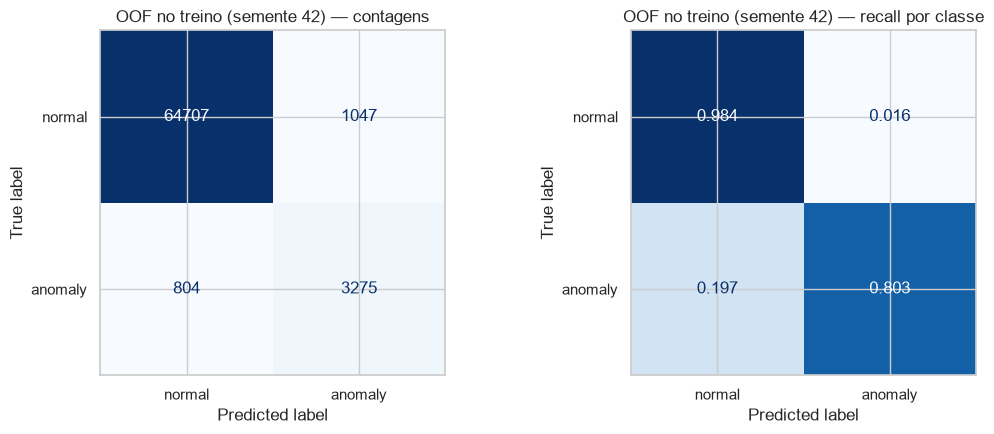

In [6]:
oof42 = oof[SEEDS[0]]
oof_labels = np.where(oof42["pred"], config.POSITIVE, "normal")
fig = validation_report(y, oof_labels, title="OOF no treino (semente 42)",
                        save_as="final_confusao_oof.png")
plt.show()

### 2.2 Por que 0,88 e não 0,98: os rótulos contraditórios

O treino tem 1.702 grupos de linhas **idênticas nos 41 atributos, mas com rótulos opostos**
(3.730 linhas). Como o modelo dá a mesma resposta para entradas iguais, pelo menos uma linha de
cada grupo sempre sai errada, seja qual for o algoritmo. Abaixo, os erros do OOF são separados
entre essas linhas e o resto, e calcula-se o **teto teórico**: o F1-macro de um classificador
que acertasse tudo fora dos conflitos e escolhesse, em cada conflito, o rótulo da maioria
(empate → `anomaly`, que rende mais F1-macro por ser a classe rara).

In [7]:
errors = oof42["pred"] != pos
majority = pd.Series(pos).groupby(groups).transform("mean").to_numpy() >= 0.5
ideal = np.where(conflict, majority, pos)
clean_rows = evaluation_mask(groups, y)
decomp = pd.DataFrame({
    "linhas": [int(conflict.sum()), int((~conflict).sum()), len(X)],
    "anomalias": [int(pos[conflict].sum()), int(pos[~conflict].sum()), int(pos.sum())],
    "erros do modelo": [int(errors[conflict].sum()), int(errors[~conflict].sum()),
                        int(errors.sum())],
    "F1-macro do modelo": [np.nan, binary_metrics(pos[~conflict], oof42["pred"][~conflict])["f1_macro"],
                           binary_metrics(pos, oof42["pred"])["f1_macro"]],
}, index=["em grupos contraditórios", "fora dos conflitos", "todas (métrica oficial)"])
display(decomp.round(4))
ceiling = binary_metrics(pos, ideal)
print(f"Teto teórico do F1-macro em todas as linhas: {ceiling['f1_macro']:.4f} "
      f"(F1 anomaly {ceiling['f1_anomaly']:.4f}, F1 normal {ceiling['f1_normal']:.4f}; "
      f"erros inevitáveis: {int((ideal != pos).sum())})")
print(f"Contraste — linhas únicas e sem conflito (evaluation_mask): F1-macro "
      f"{binary_metrics(pos[clean_rows], oof42['pred'][clean_rows])['f1_macro']:.4f}")

,linhas,anomalias,erros do modelo,F1-macro do modelo
em grupos contraditórios,3730,1896,1706,NaN
fora dos conflitos,66103,2183,145,0.9828
todas (métrica oficial),69833,4079,1851,0.8828


Teto teórico do F1-macro em todas as linhas: 0.9048 (F1 anomaly 0.8226, F1 normal 0.9869; erros inevitáveis: 1702)
Contraste — linhas únicas e sem conflito (evaluation_mask): F1-macro 0.9824


**O que se conclui.**
- **92% dos erros (1.706 de 1.851) estão nas 3.730 linhas com rótulo contraditório.** Fora delas,
  o modelo erra 145 de 66.103 linhas e o F1-macro é 0,983.
- **O teto teórico é 0,905.** Mesmo um classificador perfeito erraria 1.702 linhas (uma por
  grupo), quase todas na classe `anomaly`, que tem só 4.079 linhas: o F1 de `anomaly` não passaria
  de 0,82. O modelo, com 0,882, está a 0,02 desse teto. Por isso **0,88 não indica um modelo fraco,
  e sim o limite imposto pelo ruído de rótulo da base**.
- O F1-macro nas linhas únicas e sem conflito (0,982) é só um contraste, para medir quanto do erro
  vem do ruído. Ele **não** estima a nota do teste e não é reportado como desempenho.

### 2.3 O limiar de decisão

O modelo devolve P(anomaly) e o limiar converte essa probabilidade em classe. O padrão 0,5 só é
o melhor corte para acurácia com classes equilibradas. Aqui a métrica é F1-macro e `anomaly` é
5,8% das linhas, então o limiar é escolhido por validação cruzada. A curva abaixo mostra o
F1-macro OOF (semente 42) em cada limiar, em todas as linhas e só fora dos conflitos.

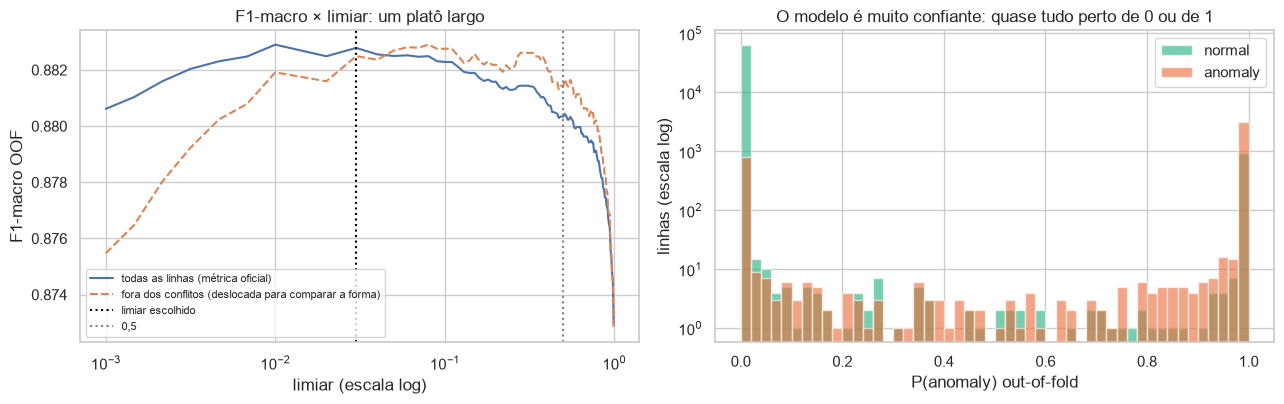

,limiar,F1-macro (todas),F1-macro (fora dos conflitos),precisão anomaly (fora),recall anomaly (fora),previstas anomaly
0,0.01,0.8829,0.9822,0.9618,0.9693,4360
1,0.03,0.8828,0.9828,0.9705,0.9629,4322
2,0.05,0.8825,0.9830,0.9731,0.9611,4300
3,0.08,0.8825,0.9832,0.9753,0.9597,4290
4,0.20,0.8816,0.9825,0.9811,0.9514,4250
5,0.50,0.8803,0.9817,0.9885,0.9418,4191


Linhas com P(anomaly) entre 0,03 e 0,5: {'normal fora dos conflitos': 40, 'anomaly fora dos conflitos': 46, 'em conflitos': 45}


In [8]:
p42 = oof42["proba"]
grid = np.unique(np.r_[np.geomspace(0.001, 0.01, 7), GRID])
curve_all = macro_f1_curve(p42, pos, grid)
curve_clean = macro_f1_curve(p42[~conflict], pos[~conflict], grid)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(grid, curve_all, label="todas as linhas (métrica oficial)")
axes[0].plot(grid, curve_clean - (curve_clean.max() - curve_all.max()), ls="--",
             label="fora dos conflitos (deslocada para comparar a forma)")
axes[0].axvline(best_threshold(p42, pos), color="black", ls=":", label="limiar escolhido")
axes[0].axvline(0.5, color="grey", ls=":", label="0,5")
axes[0].set_xscale("log")
axes[0].set_xlabel("limiar (escala log)")
axes[0].set_ylabel("F1-macro OOF")
axes[0].set_title("F1-macro × limiar: um platô largo")
axes[0].legend(fontsize=8)
bins = np.linspace(0, 1, 51)
for cls, color in [("normal", "#1baf7a"), (config.POSITIVE, "#eb6834")]:
    axes[1].hist(p42[(y == cls).to_numpy()], bins=bins, alpha=0.6, color=color, label=cls, log=True)
axes[1].set_xlabel("P(anomaly) out-of-fold")
axes[1].set_ylabel("linhas (escala log)")
axes[1].set_title("O modelo é muito confiante: quase tudo perto de 0 ou de 1")
axes[1].legend()
fig.tight_layout()
fig.savefig(config.FIGURES / "final_limiar.png", dpi=150, bbox_inches="tight")
plt.show()

table = []
for t in [0.01, 0.03, 0.05, 0.08, 0.2, 0.5]:
    a = binary_metrics(pos, p42 >= t)
    c = binary_metrics(pos[~conflict], p42[~conflict] >= t)
    table.append({"limiar": t, "F1-macro (todas)": a["f1_macro"],
                  "F1-macro (fora dos conflitos)": c["f1_macro"],
                  "precisão anomaly (fora)": c["precision_anomaly"],
                  "recall anomaly (fora)": c["recall_anomaly"],
                  "previstas anomaly": int((p42 >= t).sum())})
display(pd.DataFrame(table).round(4))
band = (p42 >= 0.03) & (p42 < 0.5)
print("Linhas com P(anomaly) entre 0,03 e 0,5:",
      {"normal fora dos conflitos": int((band & ~pos & ~conflict).sum()),
       "anomaly fora dos conflitos": int((band & pos & ~conflict).sum()),
       "em conflitos": int((band & conflict).sum())})

**O que se conclui.**
- **O limiar é baixo (0,03) porque o modelo é muito confiante.** O histograma mostra quase todas
  as linhas com P(anomaly) perto de 0 ou de 1. Entre 0,03 e 0,5 há só 131 linhas (40 normais e
  46 ataques fora dos conflitos, e 45 em conflitos). Baixar o corte de 0,5 para 0,03 muda a decisão
  só dessas linhas, e nelas há mais ataques que conexões normais.
- O modelo subestima P(anomaly) nos casos duvidosos porque aprende com 16 conexões normais para
  cada ataque: na dúvida, "normal" é o palpite mais seguro para ele. O limiar corrige essa
  tendência na decisão, sem reamostrar os dados, e é por isso que o balanceamento (SMOTE,
  undersampling, class_weight) não ajudou na Etapa 2.
- **Não é efeito dos conflitos:** mesmo fora deles o melhor limiar é baixo (0,08), e a tabela
  mostra o mesmo ganho (de 0,9817 em 0,5 para 0,983 entre 0,03 e 0,08).
- **A curva é um platô:** entre 0,01 e 0,08 o F1-macro varia menos de 0,0005, e 0,5 custa só 0,0025.
  A escolha exata pesa pouco, então o limiar não é um ponto frágil se o teste for um pouco
  diferente do treino.

### 2.4 O que esperar no teste

A CV estima o F1-macro no teste **supondo que o teste venha da mesma distribuição do treino**,
inclusive com a mesma proporção de rótulos contraditórios. Sem os rótulos, não há como verificar
isso, e o resultado oficial pode cair em três cenários:

| Cenário do teste | F1-macro esperado |
|---|---|
| Gerado como o treino (cópias e rótulos contraditórios na mesma proporção) | **≈ 0,88** (faixa dos folds: 0,874 a 0,887) |
| Com menos conflitos ou rótulos limpos | acima de 0,88, até perto de 0,98 (F1 fora dos conflitos) |
| Com distribuição diferente (outros ataques, outro perfil de tráfego) | abaixo; a CV não consegue prever |

O primeiro cenário é a hipótese de trabalho e a estimativa que reportamos. O valor de 0,8819 vem
do melhor de 20 sorteios de hiperparâmetros avaliados nos mesmos folds, então tem um pequeno
otimismo de seleção (da ordem de 0,001, menor que o desvio entre folds). O ruído de rótulo é o
mesmo para todas as equipes: derruba o valor absoluto, mas não muda a ordem dos modelos.

## 3. Treino do modelo final

O modelo final é ajustado no **treino completo** (69.833 linhas). `ThresholdClassifier`:
1. faz uma CV agrupada de 5 folds no treino e escolhe o limiar de maior F1-macro nas previsões
   out-of-fold, em todas as linhas;
2. ajusta o pipeline no treino inteiro;
3. na previsão, classifica como `anomaly` quando P(anomaly) ≥ limiar.

O modelo ajustado é salvo em `results/models/final.joblib`.

In [9]:
t0 = time.time()
final = ThresholdClassifier(build_final(), n_splits=5, n_jobs=FOLD_JOBS).fit(X, y)
print(f"Ajustado em {time.time() - t0:.0f} s | limiar aprendido: {final.threshold_:.2f}")
assert np.isclose(final.threshold_, best_threshold(p42, pos)), "limiar diferente do OOF da semente 42"
joblib.dump(final, config.MODELS / "final.joblib")
inner = final.estimator_
print("Linhas usadas no ajuste após drop_inconsistent:",
      inner.named_steps["redundancy"].fit_resample(X, y)[0].shape[0], "de", len(X))

Ajustado em 19 s | limiar aprendido: 0.03


Linhas usadas no ajuste após drop_inconsistent: 55064 de 69833


O limiar aprendido no treino inteiro é o mesmo da curva da Seção 2.3 (a CV interna usa a mesma
semente). A remoção de cópias e conflitos acontece só aqui, no ajuste: o teste passa inteiro pelo
modelo.

## 4. Submissão (único uso do teste)

O teste é carregado agora, **pela primeira e única vez**: `load_test(final_evaluation=True)`
devolve os 41 atributos de rede e os ids, sem remover nem reordenar linhas. As colunas de
vazamento que existem no arquivo são descartadas na leitura. O modelo já ajustado só faz
`predict`: nada é aprendido do teste.

In [10]:
# [TESTE]
X_te, ids = load_test(final_evaluation=True)
assert list(X_te.columns) == config.FEATURES
print("Teste:", X_te.shape, "| ids únicos:", ids.nunique())
y_te = final.predict(X_te)
submission = write_submission(ids, y_te)
sha256 = check_submission()
(config.RESULTS / f"submissao_{config.TEAM_NUMBER}.sha256").write_text(
    f"{sha256}  {config.SUBMISSION_FILE.name}\n", encoding="utf-8")
print(f"Arquivo: results/{config.SUBMISSION_FILE.name}")
print(f"SHA-256: {sha256}")
display(submission.head())

Teste: (24333, 41) | ids únicos: 24333


Arquivo: results/submissao_7.csv
SHA-256: 96f79a09d97055957ac1f85195fa0babb478c873eb38375a8c984aa4a35ef363


,id,class_prevista
0,3,normal
1,6,normal
2,9,normal
3,14,anomaly
4,17,normal


`write_submission` confere o formato da Seção 3.1 do enunciado contra `modelo_de_submissao.csv`
antes de gravar: colunas `id,class_prevista`, mesmos ids na mesma ordem, sem repetidos nem
vazios, rótulos `normal`/`anomaly` em minúsculas. `check_submission` relê o arquivo gravado,
valida de novo e devolve o SHA-256. **Esse hash identifica o arquivo enviado ao Canvas**: o
arquivo precisa ter exatamente esse hash, e reexecutar este notebook gera os mesmos bytes.

Verificações sem rótulos, só para pegar erro grosseiro (o limiar **não** é ajustado por elas):

In [11]:
# [TESTE]
p_te = positive_proba(final, X_te)
sanity = pd.DataFrame({
    "linhas": [len(X), len(X_te)],
    "% anomaly (rótulo / previsão)": [100 * pos.mean(), 100 * (y_te == config.POSITIVE).mean()],
    "% anomaly prevista no OOF": [100 * oof42["pred"].mean(), np.nan],
    "% com P entre 0,03 e 0,5": [100 * band.mean(), 100 * ((p_te >= 0.03) & (p_te < 0.5)).mean()],
}, index=["treino", "teste"])
display(sanity.round(2))
print("Previsões no teste:", pd.Series(y_te).value_counts().to_dict())

,linhas,% anomaly (rótulo / previsão),% anomaly prevista no OOF,"% com P entre 0,03 e 0,5"
treino,69833,5.84,6.19,0.19
teste,24333,4.93,NaN,0.16


Previsões no teste: {'normal': 23134, 'anomaly': 1199}


**Como ler as verificações.** A proporção de `anomaly` prevista no teste deve ficar perto da do
treino (5,8% dos rótulos, 6,2% das previsões OOF), e a fração de linhas na faixa ambígua deve ser
pequena, como no treino. Uma proporção muito diferente (por exemplo, abaixo de 3% ou acima de 10%)
indicaria erro grosseiro, como colunas trocadas ou categorias lidas de outra forma. Essas
verificações não usam rótulos e não alteram nada: o arquivo já está gravado e o limiar continua
o aprendido no treino.

## 5. Explicabilidade do modelo final

Quatro visões complementares, todas calculadas só com o treino (explicar o modelo não exige o
teste):
1. **Prova de que o vazamento saiu:** quais atributos o modelo recebe.
2. **Importância por permutação** nos atributos originais, em dados que o modelo não viu.
3. **SHAP** global (quais atributos mais pesam e em que direção) e local (por que uma conexão
   foi ou não foi classificada como ataque).
4. **Árvore substituta:** regras legíveis que imitam o modelo, com a fidelidade medida.

### 5.1 Atributos que chegam ao modelo

In [12]:
model_features = list(final.estimator_[-1].feature_names_in_)
print(f"O HistGradientBoosting recebe {len(model_features)} atributos:")
print(", ".join(model_features))
forbidden = set(config.LEAKY_COLUMNS) | set(config.DERIVED_COLUMNS)
print("\nColunas de vazamento ou derivadas entre eles:", sorted(forbidden & set(model_features)) or "nenhuma")
print("Atributos de rede fora do modelo:", sorted(set(config.FEATURES) - set(model_features)))
assert not forbidden & set(model_features)

O HistGradientBoosting recebe 40 atributos:
protocol_type, flag, service, duration, src_bytes, dst_bytes, land, wrong_fragment, urgent, hot, num_failed_logins, logged_in, num_compromised, root_shell, su_attempted, num_root, num_file_creations, num_shells, num_access_files, is_host_login, is_guest_login, count, srv_count, serror_rate, srv_serror_rate, rerror_rate, srv_rerror_rate, same_srv_rate, diff_srv_rate, srv_diff_host_rate, dst_host_count, dst_host_srv_count, dst_host_same_srv_rate, dst_host_diff_srv_rate, dst_host_same_src_port_rate, dst_host_srv_diff_host_rate, dst_host_serror_rate, dst_host_srv_serror_rate, dst_host_rerror_rate, dst_host_srv_rerror_rate

Colunas de vazamento ou derivadas entre eles: nenhuma
Atributos de rede fora do modelo: ['num_outbound_cmds']


São os 41 atributos de rede menos `num_outbound_cmds`, constante (zero) em todo o treino. Nenhuma
das 3 colunas de vazamento nem das 5 cópias derivadas chega ao modelo, então nenhuma explicação
abaixo pode depender delas.

### 5.2 Importância por permutação

Embaralhar um atributo quebra a relação dele com a classe. A queda de F1-macro mede quanto o
modelo depende dele. Para não medir memorização, o cálculo usa um modelo treinado em 4 dos 5
folds (mesmo pipeline, mesmos hiperparâmetros) e é feito no fold que ficou de fora, com o
limiar do modelo final. A permutação age nos **atributos originais**, antes da codificação.

F1-macro do fold de validação sem permutar: 0.8837 (13967 linhas, 14 s)


,queda_f1_macro,dp
service,0.0345,0.0018
dst_bytes,0.0172,0.0009
dst_host_rerror_rate,0.0066,0.0004
src_bytes,0.0063,0.0011
hot,0.0049,0.0003
duration,0.0037,0.0005
dst_host_count,0.0033,0.0007
protocol_type,0.0031,0.0004
dst_host_diff_srv_rate,0.0028,0.0006
srv_count,0.0028,0.0005


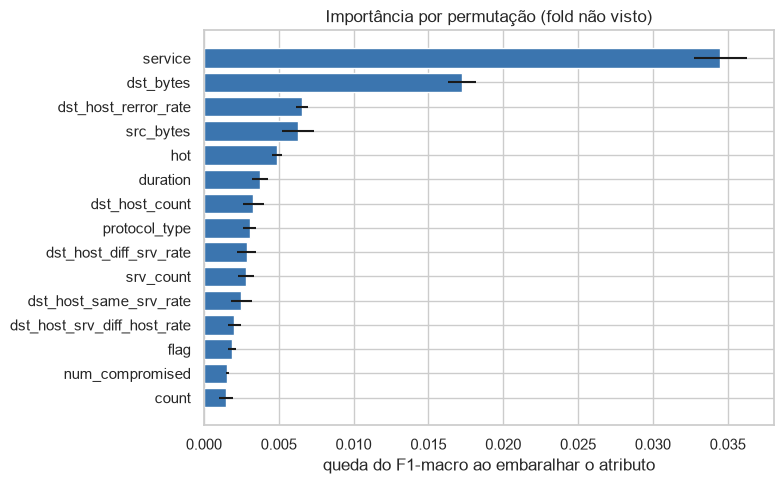

In [13]:
cv5 = StratifiedGroupKFold(5, shuffle=True, random_state=config.RANDOM_STATE)
tr, va = next(cv5.split(X, y, groups))
fold_model = build_final().fit(X.iloc[tr], y.iloc[tr])
X_va, y_va = X.iloc[va], y.iloc[va]


def f1_at_threshold(estimator, X_, y_):
    """F1-macro com o limiar do modelo final (o scorer padrão usaria 0,5)."""
    labels = np.where(positive_proba(estimator, X_) >= final.threshold_, config.POSITIVE, "normal")
    return f1_score(y_, labels, average="macro")


t0 = time.time()
perm = permutation_importance(fold_model, X_va, y_va, scoring=f1_at_threshold, n_repeats=5,
                              random_state=config.RANDOM_STATE, n_jobs=FOLD_JOBS)
perm = pd.DataFrame({"queda_f1_macro": perm.importances_mean, "dp": perm.importances_std},
                    index=X.columns).sort_values("queda_f1_macro", ascending=False)
print(f"F1-macro do fold de validação sem permutar: {f1_at_threshold(fold_model, X_va, y_va):.4f} "
      f"({len(va)} linhas, {time.time() - t0:.0f} s)")
display(perm.head(15).round(4))

fig, ax = plt.subplots(figsize=(8, 5))
top = perm.head(15).iloc[::-1]
ax.barh(top.index, top["queda_f1_macro"], xerr=top["dp"], color="#3b75af")
ax.set_xlabel("queda do F1-macro ao embaralhar o atributo")
ax.set_title("Importância por permutação (fold não visto)")
fig.tight_layout()
fig.savefig(config.FIGURES / "final_permutacao.png", dpi=150, bbox_inches="tight")
plt.show()

**O que se conclui.**
- **`service` é de longe o atributo mais importante:** embaralhá-lo derruba o F1-macro em 0,035.
  Vários ataques do NSL-KDD têm alvo característico (`private`, `ecr_i`, `telnet`, `ftp_data`),
  então o serviço sozinho já separa boa parte das classes.
- Depois vêm os **volumes** (`dst_bytes`, `src_bytes`), as **taxas de erro por host**
  (`dst_host_rerror_rate`) e atributos de conteúdo como `hot` (indicadores "quentes" na sessão,
  sinal de ataques de acesso remoto).
- As quedas são pequenas em valor absoluto porque os atributos são redundantes entre si: quando um
  é embaralhado, outros correlacionados (por exemplo, `flag` e as taxas de `serror`) compensam
  parte da informação.

### 5.3 SHAP global

Os valores SHAP repartem a saída do modelo para uma conexão (log-odds de `anomaly`) entre os
atributos: valor positivo empurra para ataque, negativo para normal, e a soma dos valores mais a
média de referência dá exatamente a saída do modelo. Usamos o explicador por **permutação** do
pacote `shap`, que só consulta o modelo e é exato para qualquer estimador. O `TreeExplainer`
foi descartado: ele não reproduz as divisões categóricas nativas do HistGradientBoosting (a soma
dos valores não batia com a saída do modelo; ver `tests/test_leakage.py`). Amostra: 1.000 linhas
do treino, com 100 linhas de referência.

SHAP em 1000 linhas (44 s); maior diferença entre a soma dos valores e a saída do modelo: 6.4e-14


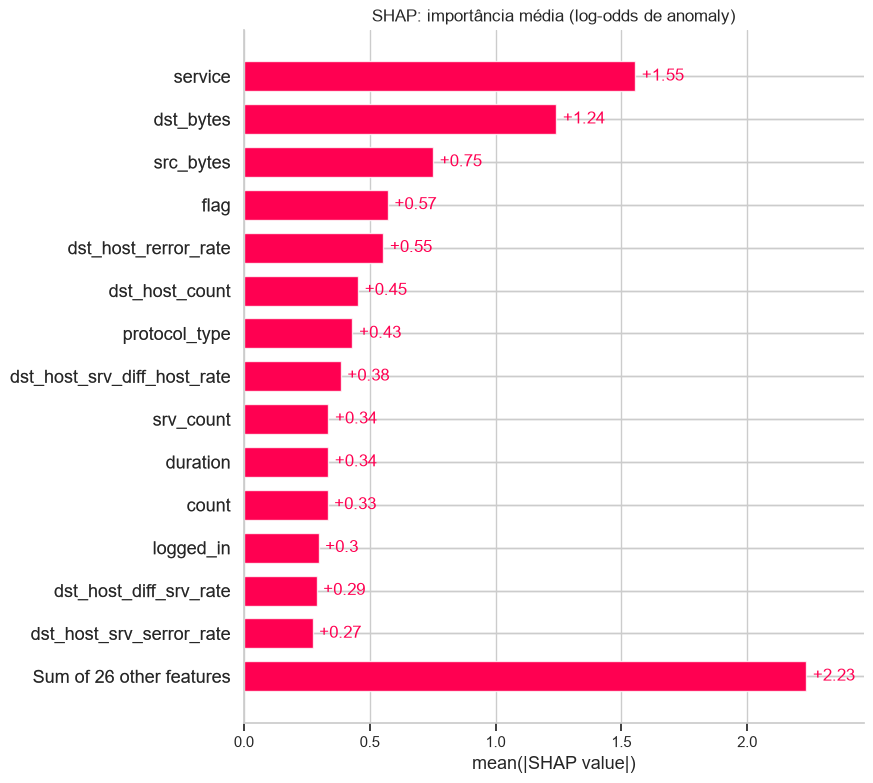

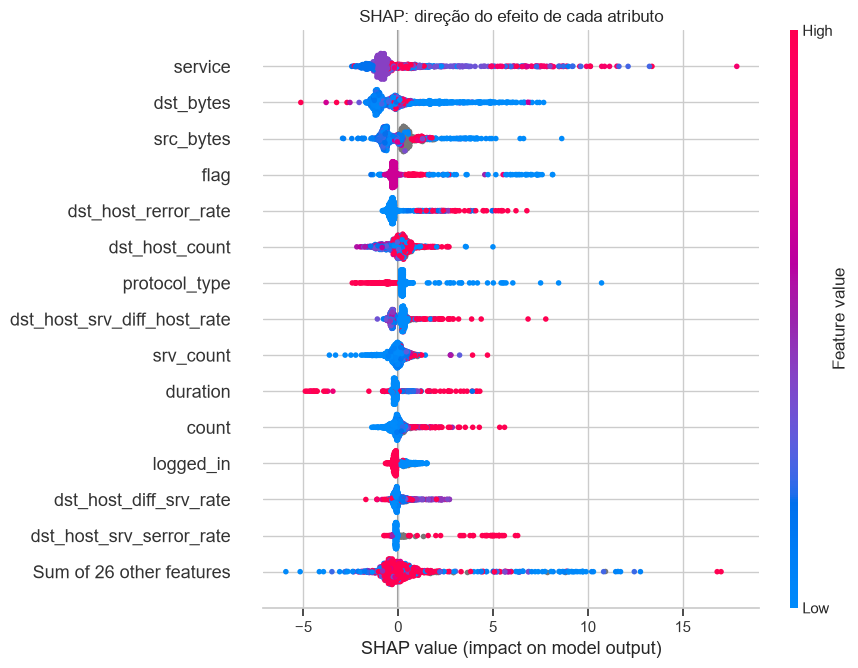

,posição SHAP,posição permutação
service,1,1
dst_bytes,2,2
src_bytes,3,4
flag,4,13
dst_host_rerror_rate,5,3
dst_host_count,6,7
protocol_type,7,8
dst_host_srv_diff_host_rate,8,12
srv_count,9,10
duration,10,6


In [14]:
t0 = time.time()
sv, Xt_shap = shap_values(final, X, sample=1000, background=100)
f_final = anomaly_log_odds(final.estimator_[-1], list(Xt_shap.columns))
gap = np.abs(sv.values.sum(axis=1) + sv.base_values - f_final(Xt_shap.to_numpy())).max()
print(f"SHAP em {len(Xt_shap)} linhas ({time.time() - t0:.0f} s); maior diferença entre a soma "
      f"dos valores e a saída do modelo: {gap:.1e}")
shap_rank = pd.Series(np.abs(sv.values).mean(axis=0), index=Xt_shap.columns,
                      name="média |SHAP|").sort_values(ascending=False)

fig = plt.figure()
shap.plots.bar(sv, max_display=15, show=False)
plt.title("SHAP: importância média (log-odds de anomaly)")
plt.savefig(config.FIGURES / "final_shap_barras.png", dpi=150, bbox_inches="tight")
plt.show()
fig = plt.figure()
shap.plots.beeswarm(sv, max_display=15, show=False)
plt.title("SHAP: direção do efeito de cada atributo")
plt.savefig(config.FIGURES / "final_shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

compare = pd.DataFrame({"posição SHAP": range(1, 16)}, index=shap_rank.index[:15])
compare["posição permutação"] = [list(perm.index).index(c) + 1 for c in compare.index]
display(compare)

**O que se conclui.**
- **SHAP e permutação concordam no topo:** `service`, `dst_bytes` e `src_bytes` estão nas quatro
  primeiras posições nas duas medidas. `flag` sobe no SHAP (4º contra 13º): ela muda muito a
  saída do modelo, mas a informação dela se repete nas taxas de `serror`, então embaralhá-la
  sozinha custa pouco F1.
- **Direção dos efeitos** (beeswarm, cor = valor do atributo): poucos bytes de resposta
  (`dst_bytes` baixo, azul) empurram para ataque, típico de varreduras e de conexões recusadas;
  taxas de erro altas (`dst_host_rerror_rate`, `dst_host_srv_serror_rate`, vermelho) também
  empurram para ataque, como em SYN flood e varredura de portas; `logged_in = 1` empurra para
  normal. Para `service`, `flag` e `protocol_type`, a cor é o código ordinal da categoria e não tem
  significado de "alto/baixo": vale a posição horizontal.
- Os atributos de maior peso são os que a literatura de detecção de intrusão aponta (serviço,
  flag, volumes e taxas de erro). O modelo aprendeu padrões de tráfego, não artefatos da base.

### 5.4 SHAP local: um acerto e um erro

Duas conexões do fold de validação da Seção 5.2, explicadas pelo modelo que **não** as viu no
treino (o mesmo modelo de fold): um ataque detectado e um ataque que passou despercebido
(falso negativo), ambos fora dos grupos contraditórios.

No fold: 426 ataques detectados e 15 não detectados fora dos conflitos


,protocol_type,service,flag,src_bytes,dst_bytes,count,srv_count,hot,num_failed_logins,logged_in,dst_host_count,dst_host_srv_count,P(anomaly)
acerto (ataque detectado),tcp,daytime,S0,0.0,0,276.0,16.0,0,0,0.0,255.0,16.0,1.000000
erro (ataque não detectado),tcp,telnet,SF,NaN,2376,1.0,1.0,0,0,NaN,255.0,254.0,0.003151


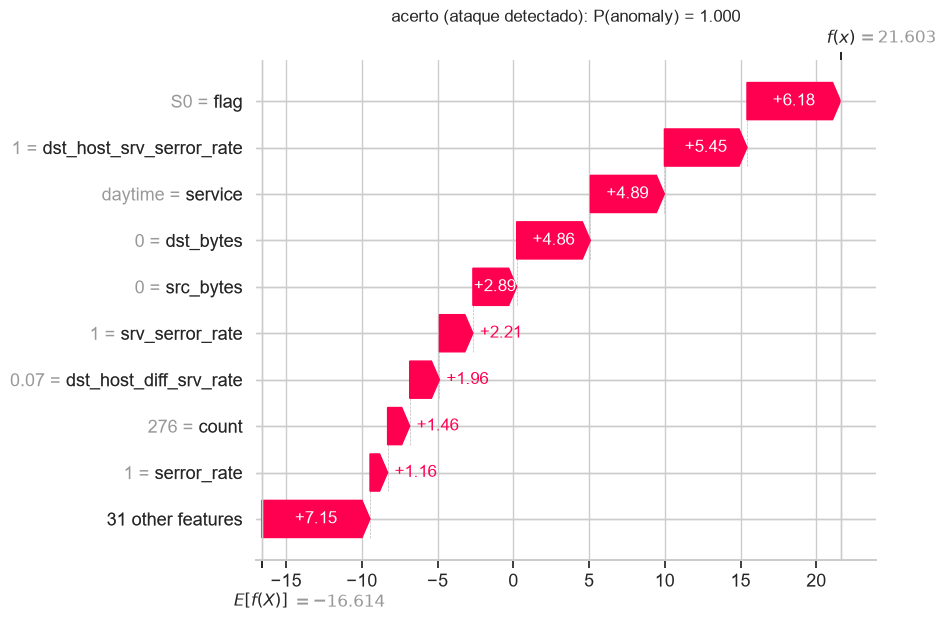

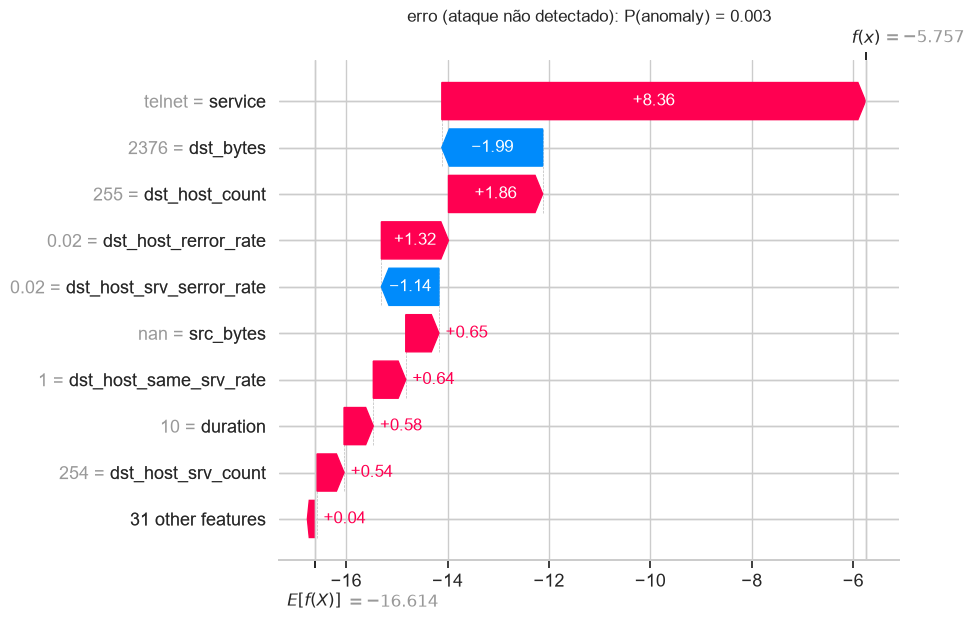

In [15]:
p_va = positive_proba(fold_model, X_va)
pos_va, conf_va = pos[va], conflict[va]
hit = np.flatnonzero(pos_va & ~conf_va & (p_va >= final.threshold_))
miss = np.flatnonzero(pos_va & ~conf_va & (p_va < final.threshold_))
rng = np.random.default_rng(config.RANDOM_STATE)
chosen = {"acerto (ataque detectado)": rng.choice(hit), "erro (ataque não detectado)": rng.choice(miss)}
print(f"No fold: {len(hit)} ataques detectados e {len(miss)} não detectados fora dos conflitos")

bg = transformed(fold_model, X.iloc[tr].sample(100, random_state=config.RANDOM_STATE))
cols = list(bg.columns)
local_explainer = shap.Explainer(anomaly_log_odds(fold_model[-1], cols),
                                 shap.maskers.Independent(bg, max_samples=100),
                                 algorithm="permutation", seed=config.RANDOM_STATE)
show_cols = ["protocol_type", "service", "flag", "src_bytes", "dst_bytes", "count", "srv_count",
             "hot", "num_failed_logins", "logged_in", "dst_host_count", "dst_host_srv_count"]
display(pd.DataFrame({name: X_va.iloc[i][show_cols] for name, i in chosen.items()}).T
        .assign(**{"P(anomaly)": [p_va[i] for i in chosen.values()]}))
for k, (name, i) in enumerate(chosen.items()):
    row = transformed(fold_model, X_va.iloc[[i]])
    explanation = local_explainer(row, max_evals=2 * len(cols) + 1, silent=True)[0]
    explanation.data = X_va.iloc[i][cols].to_numpy(dtype=object)  # categorias por nome no gráfico
    fig = plt.figure()
    shap.plots.waterfall(explanation, max_display=10, show=False)
    plt.title(f"{name}: P(anomaly) = {p_va[i]:.3f}")
    plt.savefig(config.FIGURES / f"final_shap_local_{k + 1}.png", dpi=150, bbox_inches="tight")
    plt.show()

**O que se conclui.**
- **Acerto:** conexão TCP ao serviço `daytime` com flag `S0` (pedido de abertura sem resposta),
  sem bytes trocados, 276 conexões ao mesmo destino em 2 segundos e taxa de erro de SYN igual a 1
  no host. É o perfil de um SYN flood (negação de serviço): o modelo dá P(anomaly) = 1,000, e
  todos os atributos principais (`flag = S0`, `dst_host_srv_serror_rate = 1`, o serviço e os bytes
  zerados) empurram para ataque.
- **Erro:** sessão `telnet` com flag `SF` (conexão concluída normalmente), 2.376 bytes de resposta
  e nenhum indicador de conteúdo (`hot` = 0, `num_failed_logins` = 0). O serviço `telnet` empurra
  forte para ataque (+8,4 em log-odds), mas todo o resto parece uma sessão comum e o modelo fica em
  P(anomaly) = 0,003. Ataques de acesso remoto que seguem o protocolo à risca são indistinguíveis
  de uso legítimo pelos atributos de tráfego; o sinal estaria no conteúdo da sessão.
- Os erros fora dos conflitos são poucos (15 ataques não detectados neste fold) e seguem esse
  padrão: ataques "silenciosos" que imitam tráfego comum.

### 5.5 Árvore substituta

Uma árvore de decisão rasa (profundidade 4) é treinada para imitar as **previsões** do modelo
final no treino (não os rótulos). Ela usa os atributos originais, com os categóricos em one-hot,
para que as regras sejam legíveis. A fidelidade é a fração de linhas em que a árvore concorda
com o modelo.

In [16]:
rules, fidelity = surrogate_rules(final, X, max_depth=4)
agree = final.predict(X)
print(f"Fidelidade da árvore substituta (profundidade 4): {fidelity:.4f} "
      f"(prever sempre 'normal' concordaria em {np.mean(agree == 'normal'):.4f})")
print(rules)

Fidelidade da árvore substituta (profundidade 4): 0.9844 (prever sempre 'normal' concordaria em 0.9379)
|--- dst_host_srv_serror_rate <= 0.98
|   |--- same_srv_rate <= 0.11
|   |   |--- flag_SF <= 0.50
|   |   |   |--- dst_host_diff_srv_rate <= 0.04
|   |   |   |   |--- class: normal
|   |   |   |--- dst_host_diff_srv_rate >  0.04
|   |   |   |   |--- class: anomaly
|   |   |--- flag_SF >  0.50
|   |   |   |--- dst_host_rerror_rate <= 0.16
|   |   |   |   |--- class: normal
|   |   |   |--- dst_host_rerror_rate >  0.16
|   |   |   |   |--- class: anomaly
|   |--- same_srv_rate >  0.11
|   |   |--- protocol_type_icmp <= 0.50
|   |   |   |--- flag_RSTR <= 0.50
|   |   |   |   |--- class: normal
|   |   |   |--- flag_RSTR >  0.50
|   |   |   |   |--- class: anomaly
|   |   |--- protocol_type_icmp >  0.50
|   |   |   |--- srv_count <= 12.50
|   |   |   |   |--- class: normal
|   |   |   |--- srv_count >  12.50
|   |   |   |   |--- class: anomaly
|--- dst_host_srv_serror_rate >  0.98
|   |-

**O que se conclui.**
- Com só 4 níveis, a árvore concorda com o modelo em **98,4%** das linhas (prever sempre `normal`
  concordaria em 93,8%). As regras resumem bem a lógica do modelo:
  - **`dst_host_srv_serror_rate` > 0,98 → `anomaly`** (salvo flags `S1`/`S2`, de conexões que
    chegaram a ser estabelecidas): quase todas as conexões ao serviço daquele host terminaram em
    erro de SYN, assinatura de SYN flood;
  - **`same_srv_rate` ≤ 0,11 → `anomaly`** quando, fora da flag `SF`, `dst_host_diff_srv_rate`
    > 0,04, ou, com `SF`, `dst_host_rerror_rate` > 0,16: poucas conexões ao mesmo serviço, muitos
    serviços diferentes ou rejeições, assinatura de varredura de portas;
  - **ICMP com `srv_count` > 12 → `anomaly`**: rajada de pings ao mesmo serviço (smurf, ipsweep);
  - **flag `RSTR`** (conexão abortada pelo cliente) → `anomaly`.
- A árvore é só uma explicação aproximada: a previsão enviada é a do HistGradientBoosting.

## 6. Discussão dos resultados

**Resultado esperado.** O F1-macro esperado no teste é **≈ 0,88** (CV agrupada 3×5: 0,8819 ±
0,0030), supondo que o teste tenha o mesmo ruído do treino. Se o teste tiver menos rótulos
contraditórios, o valor sobe na direção de 0,98; se tiver outro perfil de tráfego, pode cair. O
F1-macro de 0,88 está a 0,02 do teto de 0,905 que os 1.702 grupos de rótulos contraditórios
impõem a qualquer classificador.

**Como o número foi obtido, e por que confiar nele.**
1. Validação cruzada **agrupada por duplicata**: as 13.067 cópias nunca ficam em lados opostos.
2. **Todo o pré-processamento dentro do pipeline**, ajustado só nos folds de treino, inclusive a
   remoção de cópias e conflitos.
3. **Limiar cruzado:** cada fold é pontuado com um limiar escolhido nos outros folds.
4. **Métrica em todas as linhas**, como a oficial. Nas entregas das Etapas 2 e 3, a métrica
   principal era calculada só nas linhas únicas e sem conflito (~0,98), o que superestimava a nota;
   em 24/11 corrigimos e recalculamos todos os experimentos, antes do congelamento.
5. **Teste usado uma vez**, depois do congelamento, só para `predict`.

**Custo de abrir mão das colunas de vazamento.** Na EDA (notebook 01), um HGB padrão com os 41
atributos de rede fez F1-macro 0,875; com as três colunas de vazamento, 0,891; só com elas, sem
nenhum dado de rede, 0,889. Usá-las daria cerca de +0,015 no ranking. Elas foram excluídas porque
são posteriores ao evento (triagem do SOC, tempo de resposta do analista) e se comportam como
cópias ruidosas do rótulo: um detector que depende delas só "detecta" o que o SOC já detectou, e
não funcionaria em operação.

**O que mais contribuiu** (das tabelas das Etapas 2 e 3, F1-macro de CV):
- **Limpeza de rótulos** (`drop_inconsistent`) no boosting: +0,004 sobre não tratar a redundância
  (0,8777 → 0,8821), o maior ganho de pré-processamento.
- **Limiar ajustado por CV** em vez de 0,5: +0,002 a +0,003.
- **Ausentes nativos** no HGB: empatam com a imputação pela mediana (0,8821 contra 0,8817), com
  um passo a menos.
- **Não ajudaram:** balanceamento, redução de dimensionalidade, atributos derivados, ensembles e
  algoritmos fora da disciplina. Os 11 melhores candidatos ficaram dentro de 1 desvio-padrão;
  escolhemos o mais simples.

**Limitações.**
- O rótulo verdadeiro das linhas contraditórias é desconhecido, e o ruído de rótulo pode existir
  também em linhas sem cópia, onde não há como detectá-lo.
- 40% dos valores de `src_bytes` e de `dst_host_srv_count` estão ausentes; o modelo usa a ausência
  como informação, mas perde o valor.
- A estimativa supõe que o teste tenha a mesma distribuição do treino; ataques de tipos novos
  ficariam fora do que a CV mede.
- Ataques de acesso remoto que seguem o protocolo normalmente (Seção 5.4) são o principal erro
  restante e não têm sinal claro nos atributos de tráfego.

**Trabalhos futuros** (ideias que **não** entraram no modelo submetido):
- Calibração das probabilidades (Platt ou isotônica), para que P(anomaly) tenha leitura direta.
- Modelos robustos a ruído de rótulo (perdas robustas, *co-teaching*), em vez de descartar os
  conflitos.
- Atributos de conteúdo mais ricos para ataques de acesso remoto, se a base os oferecesse.

## 7. Conclusões e checklist de entrega

| Pergunta | Resposta |
|---|---|
| Modelo submetido | HistGradientBoosting (categorias e NaN nativos), `drop_inconsistent`, limiar 0,03 por CV |
| **F1-macro esperado no teste** | **0,8819 ± 0,0030** (CV agrupada 3×5, todas as linhas) |
| Métricas por classe esperadas | `normal` P 0,987 · R 0,984 · F1 0,986; `anomaly` P 0,759 · R 0,798 · F1 0,778 |
| Teto teórico da métrica | 0,905 (rótulos contraditórios) |
| Contraste fora dos conflitos | 0,983 (não é estimativa da nota) |
| Atributos mais importantes | `service`, `dst_bytes`, `src_bytes`, `flag`, taxas de erro por host |
| Colunas de vazamento no modelo | nenhuma |

A célula abaixo confere os entregáveis desta etapa.

In [17]:
sub_path = config.SUBMISSION_FILE
registered = (config.RESULTS / f"submissao_{config.TEAM_NUMBER}.sha256").read_text(encoding="utf-8").split()[0]
print("Submissão:", sub_path.relative_to(config.ROOT).as_posix(), f"({sub_path.stat().st_size} bytes)")
print("SHA-256 do arquivo:   ", check_submission())
print("SHA-256 registrado:   ", registered)
print("Modelo final salvo:   ", (config.MODELS / "final.joblib").relative_to(config.ROOT).as_posix())
print("Figuras desta etapa:  ", ", ".join(sorted(p.name for p in config.FIGURES.glob("final_*.png"))))

Submissão: results/submissao_7.csv (314229 bytes)
SHA-256 do arquivo:    96f79a09d97055957ac1f85195fa0babb478c873eb38375a8c984aa4a35ef363
SHA-256 registrado:    96f79a09d97055957ac1f85195fa0babb478c873eb38375a8c984aa4a35ef363
Modelo final salvo:    results/models/final.joblib
Figuras desta etapa:   final_confusao_oof.png, final_f1_folds.png, final_limiar.png, final_permutacao.png, final_shap_barras.png, final_shap_beeswarm.png, final_shap_local_1.png, final_shap_local_2.png


**Checklist antes do envio pelo Canvas (até 28/11):**
- [ ] Enviar `results/submissao_7.csv` sem abrir nem salvar em planilha (isso muda os bytes).
- [ ] Conferir que o arquivo enviado tem o SHA-256 impresso acima (PowerShell:
  `Get-FileHash results/submissao_7.csv`).
- [ ] Entregar este notebook executado: reexecutá-lo do início ao fim gera o mesmo arquivo
  (mesmo hash), como exige a Seção 3.1 do enunciado.
- [ ] Incluir no relatório o F1-macro esperado (0,8819 ± 0,0030), a tabela por classe e a
  declaração de uso de IA generativa (`reports/declaracao_ia.md`).

**Auditoria de vazamento deste notebook.** `python -m nslkdd.audit notebooks/04_avaliacao_final.ipynb`
retorna **0 erros** e 2 alertas, ambos legítimos: (1) na Seção 3, `fit_resample` é chamado só para
contar quantas linhas o `drop_inconsistent` mantém no ajuste; nenhum modelo é treinado com essa
saída. (2) Na Seção 5.1, as colunas de vazamento são citadas apenas para provar que não chegam ao
modelo. O teste é carregado uma única vez (Seção 4), depois do treino do modelo final.